In [138]:
import matplotlib.pyplot as plt
import numpy as np

In [139]:
# dataset
index = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
signal = np.array([-1, 1, 2, 1, 0, -1, 1, 2, 1, -2])

In [140]:
signs = [-1, 1, 1, 1, 0, -1, 1, 1, 1, -1]
diff = [signs[i] - signs[i-1] for i in range(1, len(signs))]
print("Différences entre les signes consécutifs :", diff)

Différences entre les signes consécutifs : [2, 0, 0, -1, -1, 2, 0, 0, -2]


In [141]:
def find_zero_crossings_no_zeros(signs: np.ndarray):
    """Detection des passages par zéro en utilisant les changements de signes dans un tableau de signes. Le tout en excluant les signaux nuls. 
    Elle différentie les passages par zéro positifs et négatifs."""

    # Calcule la différence entre deux signes consécutifs
    diff = np.diff(signs)

    # Une différence positive correspond à un passage de -1 à +1
    i_cross_pos = np.where(diff > 0)[0]

    # Une différence négative correspond à un passage de +1 à -1
    i_cross_neg = np.where(diff < 0)[0]

    return i_cross_pos, i_cross_neg


def propagate_signs_over_zeros(signs: np.ndarray):
    """Cette fonction permet de prendre en compte les signaux nuls dans le tableau de signes en utilisant les valeurs des signaux précédents.
    Elle prend également en compte la possibilité que le premier signal soit nul en prenant la valeur du premier signal non nul suivant.
    Une fois ces valeurs prise en compte elle permet la detection des passages par zéro positif et négatif."""

    # Copie le tableau pour ne pas modifier le tableau original
    signs_no_zeros = signs.copy()

    # Identifie les positions des valeurs non nulles
    mask = signs_no_zeros != 0

    # Conserve l'indice de chaque valeur non nulle
    idx = np.where(mask, np.arange(len(signs_no_zeros)), 0)

    # Propage le dernier indice non nul vers les positions suivantes
    idx = np.maximum.accumulate(idx)

    # Remplace les zéros par le dernier signe non nul rencontré
    signs_no_zeros = signs_no_zeros[idx]

    # Traite les zéros éventuellement présents au début du tableau
    if signs_no_zeros[0] == 0:
        # Recherche les indices des valeurs non nulles
        i_first_nonzero = np.where(signs != 0)[0]
        # Si une valeur non nulle existe, propage son signe vers le début
        if len(i_first_nonzero) > 0:
            signs_no_zeros[: i_first_nonzero[0]] = signs[i_first_nonzero[0]]

    return signs_no_zeros


def find_zero_crossings(s: np.ndarray):
    """Après s'être assuré que le tableau de signes est bien un tableau à une dimension, elle détecte les passages par zéro en utilisant les fonctions find_zero_crossings_no_zeros et propagate_signs_over_zeros."""

    # Convertit le signal en tableau NumPy
    s = np.asarray(s)

    # Vérifie que le signal possède une seule dimension
    if s.ndim != 1:
        raise ValueError("Input must be a 1D array")

    # Transforme les valeurs en signes (-1, 0 ou +1)
    signs = np.sign(s).astype(int)
    # Recherche les positions où le signal est nul
    i_zeros = np.where(signs == 0)[0]
    # Si le signal contient des zéros, détecte les passages par zéro en utilisant la propagation des signes.
    if i_zeros.size > 0:
        signs_no_zeros = propagate_signs_over_zeros(signs)
    else:
        signs_no_zeros = signs

    # Détecte les changements de signe
    return find_zero_crossings_no_zeros(signs_no_zeros)

In [142]:
def test_find_zero_crossings():
    """Test des fonctions de détection de passages par zéro. En utilisatant des signaux avec et sans passages par zéro, des alternances de signes différents sur chaque tableau de signes. ceci permet de tester la validité des fonctions utilisées avant de les utiliser sur les signaux réels."""
    s = np.array([-1, 1, -1, 1, -1])
    # expected     +  -   +  -   +
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([0, 2]))
    assert np.array_equal(i_neg, np.array([1, 3]))

    s = np.array([-1, 0, 0, 1, 0, -1])
    # expected     -     +     -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([2]))
    assert np.array_equal(i_neg, np.array([4]))

    s = np.array([0, 0, 0, 1, 0, 0])
    # expected    no crossings
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))

    s = np.array([0, 0, 1, 0, -1, 0])
    # expected             -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([3]))

    s = np.array([0, 1, 0, 0, -1, 0])
    # expected             -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([3]))

    s = np.array([1, 0, 0, -1, 0, 0])
    # expected          -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([2]))


# Testing the function
try:
    test_find_zero_crossings()
    print("All tests passed.")
except AssertionError:
    raise  # propagate the error

All tests passed.


# Role de ces tests :
ces tests permettent de vérifier qu'une fonction produit les résultats attendus selon différents scénarios.
ils servent à vérifier que la fonction find_zero_crossings identifie correctement les passages par zéro positif et négatif. Ceci est réalisé en les comparant à la fonction np.array_equal.
Si les résultats correspondent, le test réussit. Sinon, une erreur AssertionError apparait.

In [143]:
def additional_test_find_zero_crossings():
    """AUtre test de la fonction find_zero_crossings"""

    s = np.array([0,0,0,0,0])
    # expected     no crossings
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))

    s = np.array([1, 1, 1, 1, 1])
    # expected     no crossings
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))

    s = np.array([-1, -1, -1, -1, -1, -1])
    # expected    no crossings
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))

# Testing the function
try:
    test_find_zero_crossings()
    print("All tests passed.")
except AssertionError:
    raise  # propagate the error

All tests passed.


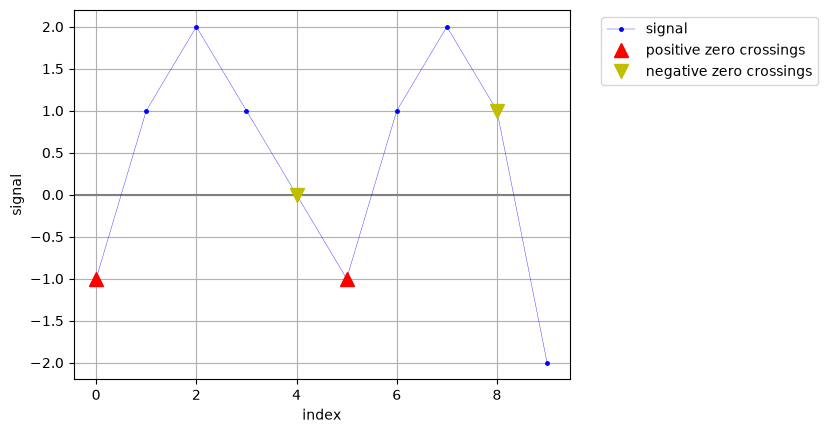

In [144]:
def plot_signal(i: np.ndarray, s: np.ndarray, color: str = "blue"):
    """Traçage du signal en fonction de l'index avec une grille et une ligne zéro. Précision des caractéristique du tracée (couleur, taille, ...)"""
    plt.axhline(y=0, color="gray", linestyle="-")  # before to be under the signal
    plt.plot(i, s, ".-", markersize=5, linewidth=0.25, color=color, label="signal")
    plt.ylabel("signal")
    plt.xlabel("index")


def plot_remarkable_points(t: np.ndarray, s: np.ndarray, format: str, label: str):
    """Traçage des points remarquables sur un signal avec un symbole et une couleur spécifique, ainsi qu'une légende pour identifier ces points sur le graphique."""
    plt.plot(t, s, format, markersize=10, label=label)


def plot_positive_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Représentation graphique des passages par zéro positifs sur un signal"""
    i_pos, _ = find_zero_crossings(s)
    plot_remarkable_points(i[i_pos], s[i_pos], "^r", "positive zero crossings")


def plot_negative_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Représentation graphique des passages par zéro négatifs sur un signal"""
    _, i_neg = find_zero_crossings(s)
    plot_remarkable_points(i[i_neg], s[i_neg], "vy", "negative zero crossings")


def plot_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Représentation graphique de tous les passages par zéro sur un signal"""
    plot_positive_zero_crossings(i, s)
    plot_negative_zero_crossings(i, s)


def display_signal_and_crossings(i: np.ndarray, s: np.ndarray):
    """Représentation graphique du signal et des passages par zéro avec une légende en dehors du graphique et une grille"""
    plt.figure()
    plot_signal(i, s)
    plot_positive_zero_crossings(i, s)
    plot_negative_zero_crossings(i, s)
    # NOTE: legend outside does not work well with %matplotlib widget
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.grid(True)
    plt.show()


# Example usage
display_signal_and_crossings(index, signal)

# Create new functions to find the local maxima and minima

In [145]:
def find_maxima(signal: np.ndarray):
    """Cette fonction détecte les maxima locaux dans un signal"""

    # Vérifie que le signal possède une seule dimension
    if signal.ndim != 1:
        raise ValueError("Input must be a 1D array")

    # Calcule la différence entre deux valeurs consécutives
    diff = np.diff(signal)

    # Trouve les indices où la différence est positive (signal en hausse) puis négative (signal en baisse)
    i_increases = np.where(diff > 0)[0]
    i_decreases = np.where(diff < 0)[0]

    # Les maxima locaux sont situés aux points où le signal passe d'une augmentation à une diminution
    i_maxima = np.intersect1d(i_increases + 1, i_decreases)

    return i_maxima, signal[i_maxima]

def find_minima(signal: np.ndarray):
    """Cette fonction détecte les minima locaux dans un signal"""

    # Vérifie que le signal possède une seule dimension
    if signal.ndim != 1:
        raise ValueError("Input must be a 1D array")

    # Calcule la différence entre deux valeurs consécutives
    diff = np.diff(signal)

    # Trouve les indices où la différence est négative (signal en baisse) puis positive (signal en hausse)
    i_decreases = np.where(diff < 0)[0]
    i_increases = np.where(diff > 0)[0]

    # Les minima locaux sont situés aux points où le signal passe d'une diminution à une augmentation
    i_minima = np.intersect1d(i_decreases + 1, i_increases)

    return i_minima, signal[i_minima]

def find_local_extrema(signal: np.ndarray):
    """Cette fonction détecte les extrema locaux (maxima et minima) dans un signal"""

    # Vérifie que le signal possède une seule dimension
    if signal.ndim != 1:
        raise ValueError("Input must be a 1D array")

    i_maxima, maxima = find_maxima(signal)
    i_minima, minima = find_minima(signal)

    return (i_maxima, maxima), (i_minima, minima)

In [146]:
def test_find_local_extrema():
    """Test de la fonction find_local_extrema avec un signal simple"""

    signal = np.array([1, 3, 2, 4, 3, 5, 4])
    (i_maxima, maxima), (i_minima, minima) = find_local_extrema(signal)
    assert np.array_equal(i_maxima, np.array([1, 3, 5]))
    assert np.array_equal(maxima, np.array([3, 4, 5]))
    assert np.array_equal(i_minima, np.array([2, 4]))
    assert np.array_equal(minima, np.array([2, 3]))

    signal = np.array([1, 5, 4, 3, 2, 1])
    (i_maxima, maxima), (i_minima, minima) = find_local_extrema(signal)
    assert np.array_equal(i_maxima, np.array([1]))
    assert np.array_equal(maxima, np.array([5]))
    assert np.array_equal(i_minima, np.array([]))
    assert np.array_equal(minima, np.array([]))

# Testing the function
try:
    test_find_local_extrema()
    print("All tests passed.")
except AssertionError:
    raise  # propagate the error

All tests passed.


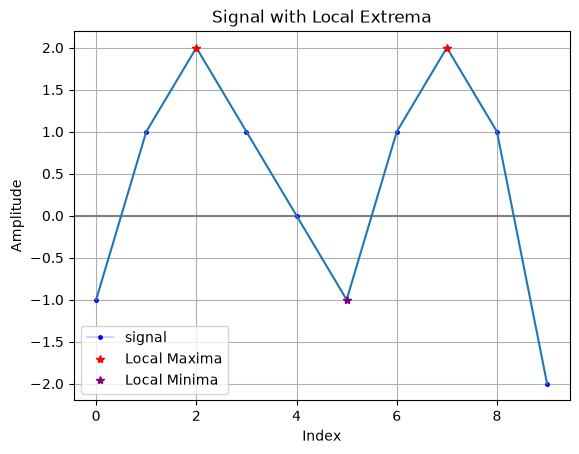

In [155]:
def plot_extrema(i: np.ndarray, s: np.ndarray):
    """Représentation graphique des extrema locaux d'un signal"""
    (i_maxima, maxima), (i_minima, minima) = find_local_extrema(s)
    plt.plot(i, s)
    plt.plot(i[i_maxima], maxima, "r*", label="Local Maxima")
    plt.plot(i[i_minima], minima, "*", color="purple", label="Local Minima")
    plt.xlabel("Index")
    plt.ylabel("Amplitude")
    plt.title("Signal with Local Extrema")
    plt.grid()
    plt.legend()
    plt.show()

def display_signal_and_extrema(i: np.ndarray, s: np.ndarray):
    """Représentation graphique du signal et de ses extrema locaux"""
    plt.figure()
    plot_signal(i, s)
    plot_extrema(i, s)
    plt.show()

# example usage
display_signal_and_extrema(index, signal)